# Assignment 6: Applying AI-Based Style Transfer to an Image
**Subject:** Generative AI

Compares two style-transfer methods on the **same photo**:
1. **CycleGAN** (pretrained *style_vangogh* model: photo → Van Gogh style)
2. **Neural Style Transfer** (VGG-19, style of *The Starry Night* by Van Gogh)


In [32]:

STUDENT_NAME = "stalin"

In [33]:
!pip -q install python-docx dominate

In [34]:
import os, io, glob, requests
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.models as models
import matplotlib.pyplot as plt
from PIL import Image
from skimage.metrics import structural_similarity as ssim
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SIZE = 512 if device.type == "cuda" else 256     # longest side of the working images
print("Device:", device, "| working image size:", SIZE)

Device: cuda | working image size: 512


## Step 1: Choose the photo and the painting

In [35]:
print("Upload ONE photo (landscape / building / object):")
uploaded = files.upload()
if uploaded:
    content_img = Image.open(list(uploaded.keys())[0]).convert("RGB")
else:
    from skimage import data
    print("No file uploaded - using a built-in sample photo instead.")
    content_img = Image.fromarray(data.coffee())

w, h = content_img.size
scale = SIZE / max(w, h)
new_size = (max(64, int(w * scale) // 4 * 4), max(64, int(h * scale) // 4 * 4))
content_img = content_img.resize(new_size, Image.LANCZOS)
print("Photo size used:", content_img.size)

Upload ONE photo (landscape / building / object):


Saving original image.png to original image (3).png
Photo size used: (512, 284)


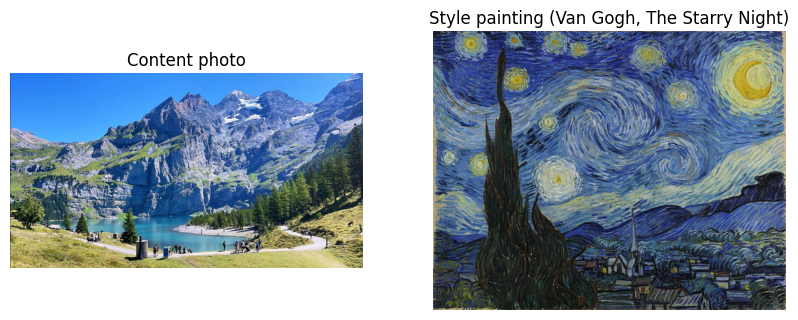

In [36]:
STYLE_URL = ("https://upload.wikimedia.org/wikipedia/commons/thumb/e/ea/"
             "Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg/1280px-Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg")

def get_style_image():
    try:
        r = requests.get(STYLE_URL, headers={"User-Agent": "Mozilla/5.0 (university assignment notebook)"}, timeout=40)
        r.raise_for_status()
        return Image.open(io.BytesIO(r.content)).convert("RGB")
    except Exception as e:
        print("Automatic download failed:", e)
        print("Please upload an image of a Van Gogh painting (e.g. The Starry Night):")
        up = files.upload()
        return Image.open(list(up.keys())[0]).convert("RGB")

style_img = get_style_image()
sw, sh = style_img.size
s = SIZE / max(sw, sh)
style_img = style_img.resize((int(sw * s), int(sh * s)), Image.LANCZOS)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(content_img); ax[0].set_title("Content photo"); ax[0].axis("off")
ax[1].imshow(style_img);   ax[1].set_title("Style painting (Van Gogh, The Starry Night)"); ax[1].axis("off")
plt.show()

## Method 1: CycleGAN (pretrained)
Uses the official pretrained **style_vangogh** CycleGAN generator (photo → Van Gogh painting) from the authors' repository.
No training is done here; the photo is passed once through the trained generator.

In [37]:
%env TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1
!git clone -q https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git
!mkdir -p pytorch-CycleGAN-and-pix2pix/checkpoints/style_vangogh_pretrained
!wget -q -O pytorch-CycleGAN-and-pix2pix/checkpoints/style_vangogh_pretrained/latest_net_G.pth http://efrosgans.eecs.berkeley.edu/cyclegan/pretrained_models/style_vangogh.pth
!ls -lh pytorch-CycleGAN-and-pix2pix/checkpoints/style_vangogh_pretrained/

env: TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD=1
fatal: destination path 'pytorch-CycleGAN-and-pix2pix' already exists and is not an empty directory.
total 44M
-rw-r--r-- 1 root root  44M Jul 24  2018 latest_net_G.pth
-rw-r--r-- 1 root root 2.5K Oct  3 17:35 test_opt.txt


----------------- Options ---------------
             aspect_ratio: 1.0                           
               batch_size: 1                             
          checkpoints_dir: ./checkpoints                 
                crop_size: 256                           
                 dataroot: ../cg_input                   	[default: None]
             dataset_mode: single                        
                direction: AtoB                          
          display_winsize: 256                           
                    epoch: latest                        
                     eval: False                         
                init_gain: 0.02                          
                init_type: normal                        
                 input_nc: 3                             
                  isTrain: False                         	[default: None]
                load_iter: 0                             	[default: 0]
                load_size: 256             

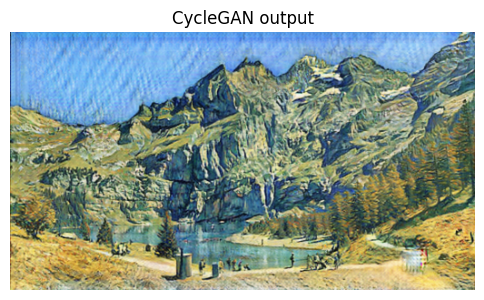

In [38]:
os.makedirs("cg_input", exist_ok=True)
content_img.save("cg_input/photo.png")


!cd pytorch-CycleGAN-and-pix2pix && python test.py --dataroot ../cg_input --name style_vangogh_pretrained --model test --dataset_mode single --no_dropout --preprocess none --num_test 1 --results_dir ../cg_results

found = glob.glob("cg_results/style_vangogh_pretrained/test_latest/images/*_fake.png")
assert found, "CycleGAN output not found - scroll up and read the error message printed above."
cyclegan_img = Image.open(found[0]).convert("RGB").resize(content_img.size, Image.LANCZOS)
plt.figure(figsize=(6, 5)); plt.imshow(cyclegan_img); plt.title("CycleGAN output"); plt.axis("off"); plt.show()

## Method 2: Neural Style Transfer (VGG-19)
Gatys-style Neural Style Transfer with a pretrained **VGG-19**:
- **Content** is matched on layer `conv4_2`.
- **Style** is matched with **Gram matrices** on `conv1_1, conv2_1, conv3_1, conv4_1, conv5_1`.
- The pixels of the output image are optimised with **L-BFGS** for 300 steps, starting from the content photo.

In [39]:
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_tensor(img):
    arr = np.asarray(img).astype(np.float32) / 255.0
    return torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(device)

def to_pil(t):
    arr = t.detach().clamp(0, 1).squeeze(0).permute(1, 2, 0).cpu().numpy()
    return Image.fromarray((arr * 255).astype(np.uint8))

vgg = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1).features.to(device).eval()
for p in vgg.parameters():
    p.requires_grad_(False)
for layer in vgg:
    if isinstance(layer, nn.ReLU):
        layer.inplace = False

STYLE_LAYERS = {0: "conv1_1", 5: "conv2_1", 10: "conv3_1", 19: "conv4_1", 28: "conv5_1"}
CONTENT_LAYER = 21   # conv4_2

def extract(x):
    x = (x - mean) / std
    feats = {}
    for i, layer in enumerate(vgg):
        x = layer(x)
        if i in STYLE_LAYERS or i == CONTENT_LAYER:
            feats[i] = x
        if i >= 28:
            break
    return feats

def gram(f):
    b, c, h, w = f.shape
    f = f.reshape(c, h * w)
    return f @ f.t() / (c * h * w)

content_t = to_tensor(content_img)
style_t = to_tensor(style_img)
with torch.no_grad():
    c_feats = extract(content_t)
    s_feats = extract(style_t)
    s_grams = {i: gram(s_feats[i]) for i in STYLE_LAYERS}

Step  50 | content loss 63.0639 | style loss 0.000160
Step 100 | content loss 54.7339 | style loss 0.000076
Step 150 | content loss 49.9570 | style loss 0.000049
Step 200 | content loss 46.4782 | style loss 0.000034
Step 250 | content loss 44.0054 | style loss 0.000026
Step 300 | content loss 42.1873 | style loss 0.000022


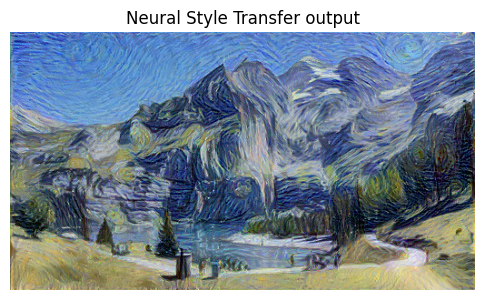

In [40]:
STYLE_WEIGHT, CONTENT_WEIGHT, STEPS = 1e6, 1.0, 300

gen = content_t.contiguous().clone().requires_grad_(True)
optimizer = torch.optim.LBFGS([gen])
step = [0]

def closure():
    with torch.no_grad():
        gen.clamp_(0, 1)
    optimizer.zero_grad()
    f = extract(gen)
    c_loss = F.mse_loss(f[CONTENT_LAYER], c_feats[CONTENT_LAYER])
    s_loss = sum(F.mse_loss(gram(f[i]), s_grams[i]) for i in STYLE_LAYERS)
    loss = CONTENT_WEIGHT * c_loss + STYLE_WEIGHT * s_loss
    loss.backward()
    gen.grad = gen.grad.contiguous()
    step[0] += 1
    if step[0] % 50 == 0:
        print(f"Step {step[0]:>3} | content loss {c_loss.item():.4f} | style loss {s_loss.item():.6f}")
    return loss

while step[0] < STEPS:
    optimizer.step(closure)

nst_img = to_pil(gen)
plt.figure(figsize=(6, 5)); plt.imshow(nst_img); plt.title("Neural Style Transfer output"); plt.axis("off"); plt.show()

## Side-by-side comparison


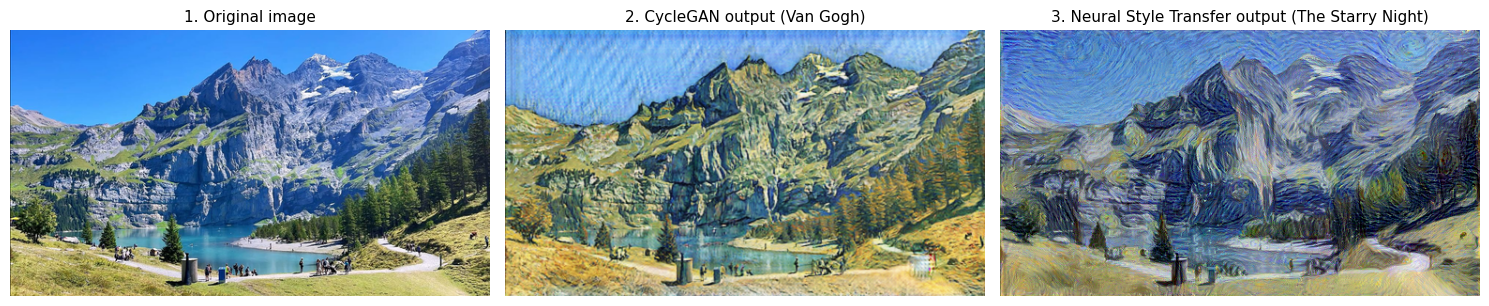

In [41]:
titles = ["1. Original image", "2. CycleGAN output (Van Gogh)", "3. Neural Style Transfer output (The Starry Night)"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, im, t in zip(axes, [content_img, cyclegan_img, nst_img], titles):
    ax.imshow(im); ax.set_title(t, fontsize=11); ax.axis("off")
plt.tight_layout()
fig.savefig("comparison.png", dpi=200, bbox_inches="tight")
plt.show()

content_img.save("original.png"); cyclegan_img.save("cyclegan_output.png"); nst_img.save("nst_output.png")
style_img.save("style_painting.png")

## Measuring the two outputs
- **Content preservation:** SSIM between each output and the original photo (higher = original structure kept better).
- **Style transformation:** how much closer the output's Gram-matrix style statistics are to the painting than the original photo was (higher % = stronger style change).
  This measures resemblance to the specific painting used, which Neural Style Transfer optimises directly, while CycleGAN learns the general style of the artist.

In [42]:
def to_gray(img):
    return np.asarray(img.convert("L")).astype(np.float64)

def content_score(img):
    return ssim(to_gray(content_img), to_gray(img), data_range=255)

def style_distance(img):
    with torch.no_grad():
        f = extract(to_tensor(img))
        return sum(F.mse_loss(gram(f[i]), s_grams[i]).item() for i in STYLE_LAYERS)

d_orig = style_distance(content_img)
ssim_cg, ssim_nst = content_score(cyclegan_img), content_score(nst_img)
gain_cg  = (1 - style_distance(cyclegan_img) / d_orig) * 100
gain_nst = (1 - style_distance(nst_img) / d_orig) * 100

print(f"{'Method':<24}{'SSIM vs original':>18}{'Style distance reduced':>26}")
print(f"{'CycleGAN':<24}{ssim_cg:>18.3f}{gain_cg:>25.1f}%")
print(f"{'Neural Style Transfer':<24}{ssim_nst:>18.3f}{gain_nst:>25.1f}%")

Method                    SSIM vs original    Style distance reduced
CycleGAN                             0.753                     41.8%
Neural Style Transfer                0.536                     99.9%


## Written comparison

In [43]:
cg_name, nst_name = "CycleGAN", "Neural Style Transfer"
if ssim_cg >= ssim_nst:
    best_content, best_c_val, other_c_val = cg_name, ssim_cg, ssim_nst
else:
    best_content, best_c_val, other_c_val = nst_name, ssim_nst, ssim_cg
if gain_cg >= gain_nst:
    best_style, best_s_val, other_s_val = cg_name, gain_cg, gain_nst
else:
    best_style, best_s_val, other_s_val = nst_name, gain_nst, gain_cg

comparison_lines = [
    f"Content preservation: {best_content} preserved the original content better, keeping a structural similarity (SSIM) of {best_c_val:.2f} with the original photo compared with {other_c_val:.2f} for the other method.",
    f"Style strength: {best_style} produced the stronger style transformation, moving the image {best_s_val:.0f}% closer to the painting's style statistics compared with {other_s_val:.0f}% for the other method.",
    "Differences: CycleGAN is a feed-forward generator that has learned the general look of Van Gogh's paintings and applies it in a single pass, typically changing colours and textures while keeping the scene layout, whereas Neural Style Transfer optimises the pixels of this one image over hundreds of iterations to copy the colours and brush-stroke textures of one specific painting, giving a more visibly painted result.",
    "Cycle consistency: CycleGAN was trained on unpaired photos and paintings, and cycle consistency (translating a photo to the painting domain and back should reproduce the original photo) forces the generator to keep the content of the input, while Neural Style Transfer controls content explicitly through its content loss on VGG features.",
]
for line in comparison_lines:
    print("-", line, "\n")

- Content preservation: CycleGAN preserved the original content better, keeping a structural similarity (SSIM) of 0.75 with the original photo compared with 0.54 for the other method. 

- Style strength: Neural Style Transfer produced the stronger style transformation, moving the image 100% closer to the painting's style statistics compared with 42% for the other method. 

- Differences: CycleGAN is a feed-forward generator that has learned the general look of Van Gogh's paintings and applies it in a single pass, typically changing colours and textures while keeping the scene layout, whereas Neural Style Transfer optimises the pixels of this one image over hundreds of iterations to copy the colours and brush-stroke textures of one specific painting, giving a more visibly painted result. 

- Cycle consistency: CycleGAN was trained on unpaired photos and paintings, and cycle consistency (translating a photo to the painting domain and back should reproduce the original photo) forces the g

## Create the submission document

In [44]:
from docx import Document
from docx.shared import Pt, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH

doc = Document()
sec = doc.sections[0]
sec.left_margin = sec.right_margin = Inches(0.8)
sec.top_margin = sec.bottom_margin = Inches(0.8)
doc.styles["Normal"].font.name = "Calibri"
doc.styles["Normal"].font.size = Pt(11)

title = doc.add_heading("Assignment 6: Applying AI-Based Style Transfer to an Image", level=0)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER
sub = doc.add_paragraph("Generative AI" + (f"  |  {STUDENT_NAME}" if STUDENT_NAME.strip() else ""))
sub.alignment = WD_ALIGN_PARAGRAPH.CENTER

doc.add_heading("Objective", level=1)
doc.add_paragraph("To compare two different methods of image style transfer, a pretrained CycleGAN and a VGG-based Neural Style Transfer, by applying the style of Van Gogh's paintings to the same photograph.")

doc.add_heading("Methods", level=1)
p = doc.add_paragraph(); p.add_run("Method 1: CycleGAN. ").bold = True
p.add_run("A pretrained CycleGAN model (style_vangogh, photo to Van Gogh painting) was applied to the photo in a single forward pass. CycleGAN learns to translate between two image domains using unpaired images. It has two generators (photo to painting and painting to photo) and two discriminators, and is trained with an adversarial loss plus a cycle-consistency loss: an image translated to the other domain and then translated back should match the original image. This cycle consistency is what keeps the content and structure of the photo while the style changes.")
p = doc.add_paragraph(); p.add_run("Method 2: Neural Style Transfer. ").bold = True
p.add_run("A pretrained VGG-19 network was used to extract features. The pixels of the output image were optimised (L-BFGS, 300 steps) so that its content matched the photo (layer conv4_2) and its style, measured with Gram matrices on layers conv1_1 to conv5_1, matched the painting The Starry Night by Vincent van Gogh.")

doc.add_heading("Results", level=1)
doc.add_picture("comparison.png", width=Inches(6.7))
doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
cap = doc.add_paragraph("Figure 1: Original image, CycleGAN output and Neural Style Transfer output (left to right).")
cap.alignment = WD_ALIGN_PARAGRAPH.CENTER
cap.runs[0].italic = True

doc.add_picture("style_painting.png", width=Inches(2.6))
doc.paragraphs[-1].alignment = WD_ALIGN_PARAGRAPH.CENTER
cap = doc.add_paragraph("Figure 2: Style painting used for Neural Style Transfer (The Starry Night, Vincent van Gogh).")
cap.alignment = WD_ALIGN_PARAGRAPH.CENTER
cap.runs[0].italic = True

table = doc.add_table(rows=3, cols=3)
table.style = "Light Grid Accent 1"
rows = [("Method", "Content preservation (SSIM, higher is better)", "Style distance reduced (higher is stronger style)"),
        ("CycleGAN", f"{ssim_cg:.3f}", f"{gain_cg:.1f}%"),
        ("Neural Style Transfer", f"{ssim_nst:.3f}", f"{gain_nst:.1f}%")]
for r_i, row in enumerate(rows):
    for c_i, val in enumerate(row):
        table.cell(r_i, c_i).text = val

doc.add_heading("Written Comparison", level=1)
for line in comparison_lines:
    doc.add_paragraph(line)

doc.save("Assignment6_Style_Transfer.docx")
print("Saved Assignment6_Style_Transfer.docx")
files.download("Assignment6_Style_Transfer.docx")

Saved Assignment6_Style_Transfer.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>